### SUPPORT VECTOR MACHINE (SVM) AND RANDOM FOREST FOR BINARY & MULTICLASS CLASSIFICATION

In [2]:
import pandas as pd 
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler 
from sklearn.svm import SVC 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [3]:
iris = load_iris()
X = iris.data
y = iris.target

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# We do feature scaling to put all data values on the same level. Without it, numbers that are large will overpower small numbers. This makes the computer think big numbers are more important, even when they are not

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

In [8]:
svm_model = SVC(kernel='linear') # You can also try 'rbf', 'poly'
svm_model.fit(X_train, y_train)

SVC(kernel='linear')

In [9]:
y_pred_svm = svm_model.predict(X_test)
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("SVM Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

SVM Accuracy: 0.9777777777777777
SVM Confusion Matrix:
 [[19  0  0]
 [ 0 12  1]
 [ 0  0 13]]


In [10]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [11]:
y_pred_rf = rf_model.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Random Forest Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 1.0
Random Forest Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


Text(0.5, 1.0, 'SVM Confusion Matrix')

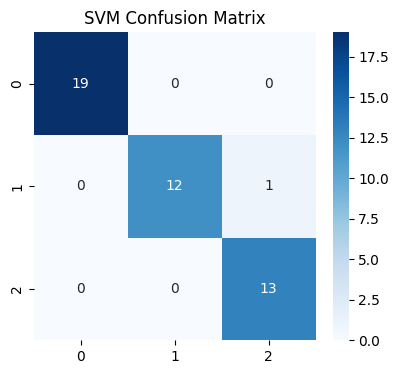

In [12]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, cmap='Blues', fmt='d')
plt.title("SVM Confusion Matrix")

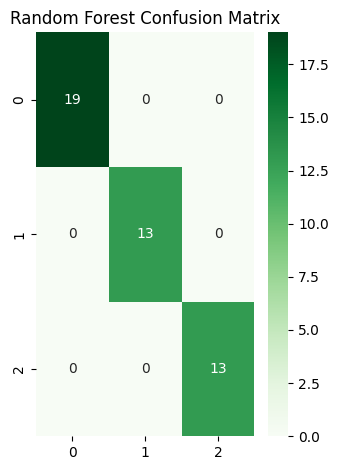

In [13]:
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, cmap='Greens', fmt='d')
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()